# Task 5 — Representation & Temporal Density Study

การทดลองใหม่บนข้อมูลไม่มี label: denoising autoencoder, PCA, latent-density estimators และ Isolation Forest

**Run All ค่าเริ่มต้นโหลดผลที่ฝึกเสร็จแล้ว** ไม่ฝึกซ้ำและไม่ส่ง Kaggle
โมเดลหลักสำหรับทดลองส่ง: multi-resolution PCA + GMM จำนวน 72 ตัว
คะแนน 0.81771 เป็นคะแนนรวมของ reference เดิม ไม่ใช่ F3 ของโมเดลใหม่นี้


## 1. Environment & Run Controls

In [1]:
from pathlib import Path
import sys, os, tempfile, json
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")
os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "task5-mpl"))
roots = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for q in roots for p in (q, q / "CPE342-Kaggle")
             if (p / "Task5/models/representation_followup.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("เปิด notebook ภายใน CPE342-Kaggle หรือกำหนด ROOT ให้ตรง project")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
RUN_TRAINING = False
RUN_FULL_VERIFICATION = False
EXPORT_CSV = False
print("Project:", ROOT)
print("Python:", sys.executable)

Project: /Users/meng/dev/MyUniversity/CPE342-MachineLearning/CPE342-Kaggle
Python: /Users/meng/dev/MyUniversity/CPE342-MachineLearning/CPE342-Kaggle/.venv/bin/python


In [2]:
import numpy as np
import pandas as pd
from IPython.display import display, Image
from Task5.models import representation_followup as study
from Task5.models import representation_refinement as refinement
from Task5.models import representation_multiscale as multiscale
from Task5.models import representation_report as report
display(pd.Series(study.CONFIG, name="Training configuration"))

Matplotlib is building the font cache; this may take a moment.


seeds         [173, 271, 389]
folds                       3
split_seed                619
epochs                     45
patience                    7
batch_size                512
lr                      0.001
latent                      8
hidden               [96, 32]
masking                   0.1
noise                    0.03
components                  6
trees                     300
budget                   2046
device                    cpu
threads                     4
Name: Training configuration, dtype: object

## 2. Raw Data Audit

In [3]:
train_unlabeled = pd.read_csv(study.RAW)
assert train_unlabeled.player_id.is_unique
assert "is_anomaly" not in train_unlabeled
display(train_unlabeled.head())
display(pd.DataFrame({"dtype": train_unlabeled.dtypes.astype(str),
                      "missing": train_unlabeled.isna().sum(),
                      "missing_fraction": train_unlabeled.isna().mean()}))

,player_id,login_count_1,login_count_2,login_count_3,login_count_4,login_lat_1,login_lon_1,login_lat_2,login_lon_2,login_lat_3,...,guild_changes_1,guild_changes_2,guild_changes_3,guild_changes_4,account_age_days,behavior_stability,password_changed,vpn_usage,suspicious_login_time,mass_item_sale
0,P024743,67.238336,27.598368,38.114171,45.320790,-55.660805,47.357425,-55.442687,46.861868,-55.882950,...,1.0,1.0,2.0,1.0,1027.683779,0.232040,0.0,0.0,0.0,1.0
1,P005319,21.039249,28.153000,20.788758,20.483913,44.210837,26.034926,43.930301,26.515108,43.442722,...,1.0,NaN,2.0,1.0,1450.873210,0.918705,0.0,1.0,0.0,0.0
2,P014970,90.268461,109.156193,96.764974,96.542496,37.371864,33.819993,37.351600,33.503336,37.044372,...,0.0,-1.0,-1.0,0.0,611.275151,0.764911,0.0,0.0,0.0,0.0
3,P003275,29.880876,28.448716,24.296107,24.403403,48.026437,-119.863672,47.992586,-118.485494,48.123361,...,2.0,1.0,2.0,2.0,404.103143,0.712205,0.0,0.0,0.0,0.0
4,P009022,62.283808,73.703985,48.331688,71.803417,39.647200,154.007807,39.675523,154.225136,38.851983,...,0.0,0.0,0.0,1.0,1091.671684,0.896939,0.0,0.0,0.0,0.0


,dtype,missing,missing_fraction
player_id,str,0,0.000000
login_count_1,float64,1217,0.047008
login_count_2,float64,1276,0.049287
login_count_3,float64,1268,0.048978
login_count_4,float64,1235,0.047704
...,...,...,...
behavior_stability,float64,1257,0.048553
password_changed,float64,1363,0.052648
vpn_usage,float64,1260,0.048669
suspicious_login_time,float64,1274,0.049210


## 3. Feature Representation

In [4]:
X, trajectory_columns = study.features(train_unlabeled)
display(pd.Series(json.loads((study.OUT / "data_audit.json").read_text())))
display(pd.DataFrame({"feature": X.columns,
                      "kind": ["temporal contrast / distance" if c in trajectory_columns else "period / static" for c in X.columns]}))

rows                            25889
raw_features                      122
engineered_features               202
trajectory_features                87
missing_raw_cells              154112
duplicated_player_ids               0
invalid_geo_rows                  218
ids_used_as_features            False
old_predictions_used_to_fit     False
dtype: object

,feature,kind
0,login_count_1,period / static
1,login_count_2,period / static
2,login_count_3,period / static
3,login_count_4,period / static
4,location_changes_1,period / static
...,...,...
197,geo__km14,temporal contrast / distance
198,geo__km23,temporal contrast / distance
199,geo__km24,temporal contrast / distance
200,geo__km34,temporal contrast / distance


- เก็บค่าทุกช่วงเวลา แปลง `asinh` เพื่อเก็บเครื่องหมายและลดผลของสเกลที่ต่างกัน
- เพิ่ม Haar contrasts: `(p2-p1)/sqrt(2)`, `(p4-p3)/sqrt(2)`, `(p3+p4-p1-p2)/2` ครอบคลุมรูปแบบเปลี่ยนแปลงทั้ง 4 ช่วง
- แทน absolute latitude/longitude ด้วยระยะทางครบ 6 คู่; invalid coordinates เป็น missing พร้อม count
- ไม่ตีความ `-1` เป็น anomaly อัตโนมัติ; ไม่ใช้ player_id หรือคำตอบเดิมเป็น predictors
- Imputer/robust scale fit เฉพาะ training fold; missing indicators เป็น context ส่วน AE loss ไม่คิดตำแหน่ง target ที่หาย
- clip หลัง scaling ที่ ±12: ลด outlier domination แต่ทำให้ magnitude ที่เกินนี้แยกกันไม่ได้


## 4. Evaluation Protocol

- 3 outer folds × 3 seeds; แต่ละแถวได้คะแนนจากโมเดลที่ไม่ฝึกบนแถวนั้น
- แยก 15% ของ outer-training เป็น reconstruction validation และ score calibration
- validation ใช้เลือก epoch และแปลงคะแนนเป็น rank จึงไม่ใช่ชุดทดสอบอิสระ; outer-held-out ยังไม่ถูกใช้ฝึก
- ทุกบัญชีใน training fold ใช้ฝึกโดยไม่มีการคัด background จาก reference; anomaly contamination ใน training ยังมีได้
- Threshold หลักใช้ **2,046 alerts** เพื่อเทียบที่ budget เท่ากัน ไม่ใช่การประมาณสัดส่วน anomaly จริง
- ไม่มี ground-truth F3: Jaccard วัดความเสถียร, synthetic AUC วัดความไวต่อ perturbation, overlap วัดความเหมือน reference เท่านั้น


## 5. Fit / Resume Base Models

In [5]:
if RUN_TRAINING:
    study.train()
else:
    needed = [study.OUT / f"seed{s}_fold{f}.joblib" for s in study.CONFIG["seeds"] for f in range(1, 4)]
    missing = [str(p) for p in needed if not p.exists()]
    if missing:
        raise FileNotFoundError(f"ขาด model bundles {len(missing)} ไฟล์; เปิด RUN_TRAINING เพื่อฝึก/resume")
summary = json.loads((study.OUT / "summary.json").read_text())
display(pd.DataFrame(summary["training"]))

,seed,fold,epochs,seconds,validation_huber,ae_gmm_converged,pca_gmm_converged
0,173,1,45,5.082444,0.300292,True,True
1,173,2,45,5.303172,0.302622,True,True
2,173,3,45,5.030038,0.298271,True,True
3,271,1,45,4.813588,0.296361,True,True
4,271,2,45,4.775804,0.295626,True,True
5,271,3,45,5.039196,0.301466,True,True
6,389,1,45,4.933323,0.296010,True,True
7,389,2,45,4.823967,0.295045,True,True
8,389,3,45,4.967089,0.303987,True,True


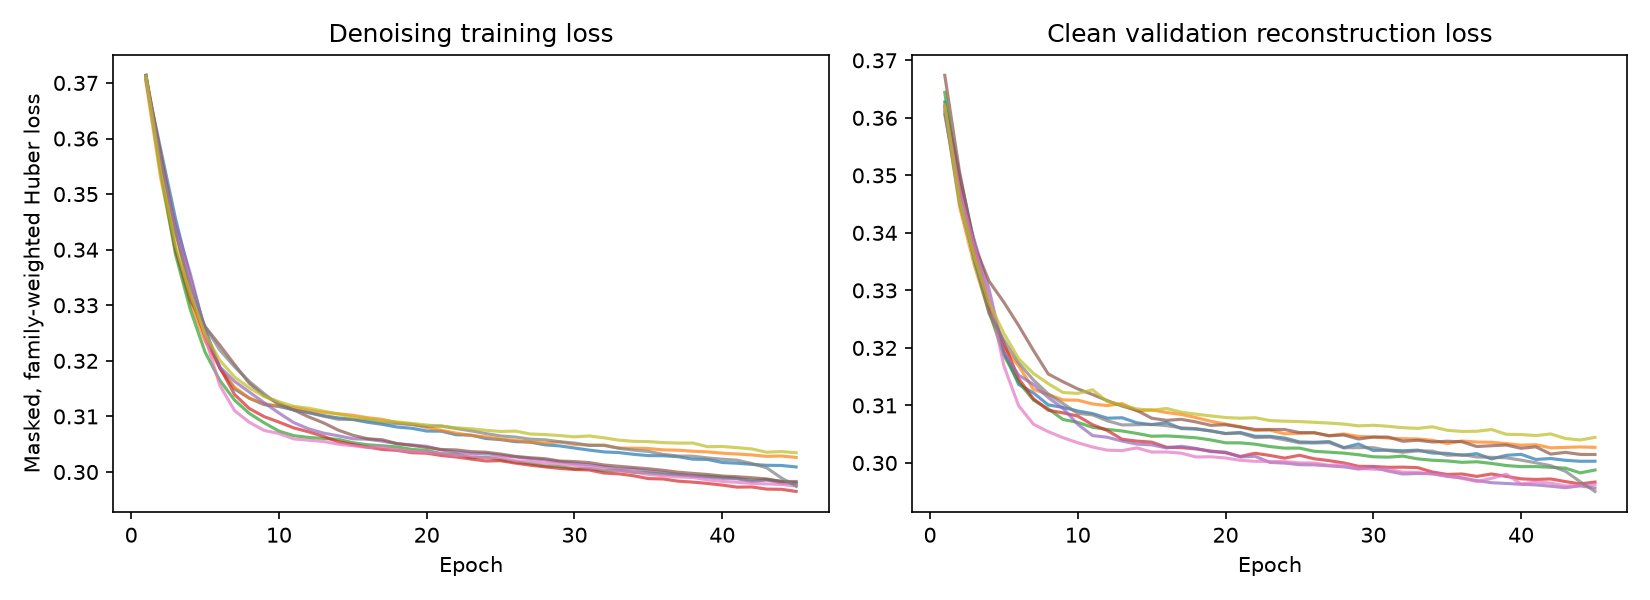

In [6]:
display(Image(filename=str(study.OUT / "figures/training_curves.png")))

AE: encoder `2×features → 96 → 32 → 8`, decoder `8 → 32 → 96 → features`;
masking 10%, Gaussian noise 0.03, family-weighted masked Huber loss, AdamW,
สูงสุด 45 epochs, patience 7. Model นี้เป็น **two-stage AE + GMM** ไม่ใช่ joint DAGMM loss.

บันทึก optimizer, current/best weights, RNG และ epoch ทุก epoch; bundle สุดท้ายเก็บ preprocessing, fold indices, calibration และโมเดลทั้งหมด


## 6. Refine Latent Density & Fit Multi-resolution Ensemble

In [7]:
if RUN_TRAINING:
    refinement.fit()
    multiscale.fit()
display(pd.read_parquet(refinement.OUT / "diagnostics.parquet"))
display(pd.Series(json.loads((multiscale.OUT / "summary.json").read_text())))

,method,alerts,retained,added,removed,seed_jaccard_mean
0,latent_knn35,2046,1306,740,740,0.552444
1,latent_gmm_tied,2046,1107,939,939,0.473678
2,latent_gmm_diag,2046,1151,895,895,0.420718
3,latent_shrinkage,2046,1361,685,685,0.625639


method               multiscale_density
models                               72
alerts                             2046
retained                           1159
added                               887
removed                             887
seed_jaccard_mean              0.880816
public_score                       None
measured_f3                        None
dtype: object

Refinement ทดลอง kNN-35, GMM tied/diagonal covariance และ Ledoit-Wolf บน AE latent.

Multi-resolution ensemble ใช้ PCA dimensions **4, 8, 16, 24** × GMM components **4, 8**, tied covariance และ regularization 0.05.
แต่ละ representation รวม PCA coordinates กับ mean-square / top-3 reconstruction error.
แปลงแต่ละ model score เป็น percentile ด้วย inner calibration แล้วเฉลี่ย 8 resolutions เท่ากัน; รวม 3 seeds ด้วย median.
ทั้งหมด 8 × 3 folds × 3 seeds = **72 GMM**.
เลือกเป็น development candidate เพราะเสถียรขึ้น ไม่ได้เลือกจาก fraud labels หรือคะแนน Kaggle ใหม่


## 7. Compare All 11 Scoring Methods

In [8]:
diagnostics = pd.read_parquet(study.OUT / "all_diagnostics.parquet")
display(diagnostics[["method", "alerts", "retained", "added", "removed", "seed_jaccard_mean"]].sort_values("seed_jaccard_mean", ascending=False))

,method,alerts,retained,added,removed,seed_jaccard_mean
10,multiscale_density,2046,1159,887,887,0.880816
2,pca_reconstruction,2046,998,1048,1048,0.847588
0,ae_reconstruction,2046,808,1238,1238,0.796427
3,pca_latent_density,2046,1048,998,998,0.688238
5,isolation_trajectory,2046,704,1342,1342,0.638795
9,latent_shrinkage,2046,1361,685,685,0.625639
4,isolation_full,2046,688,1358,1358,0.553171
6,latent_knn35,2046,1306,740,740,0.552444
7,latent_gmm_tied,2046,1107,939,939,0.473678
8,latent_gmm_diag,2046,1151,895,895,0.420718


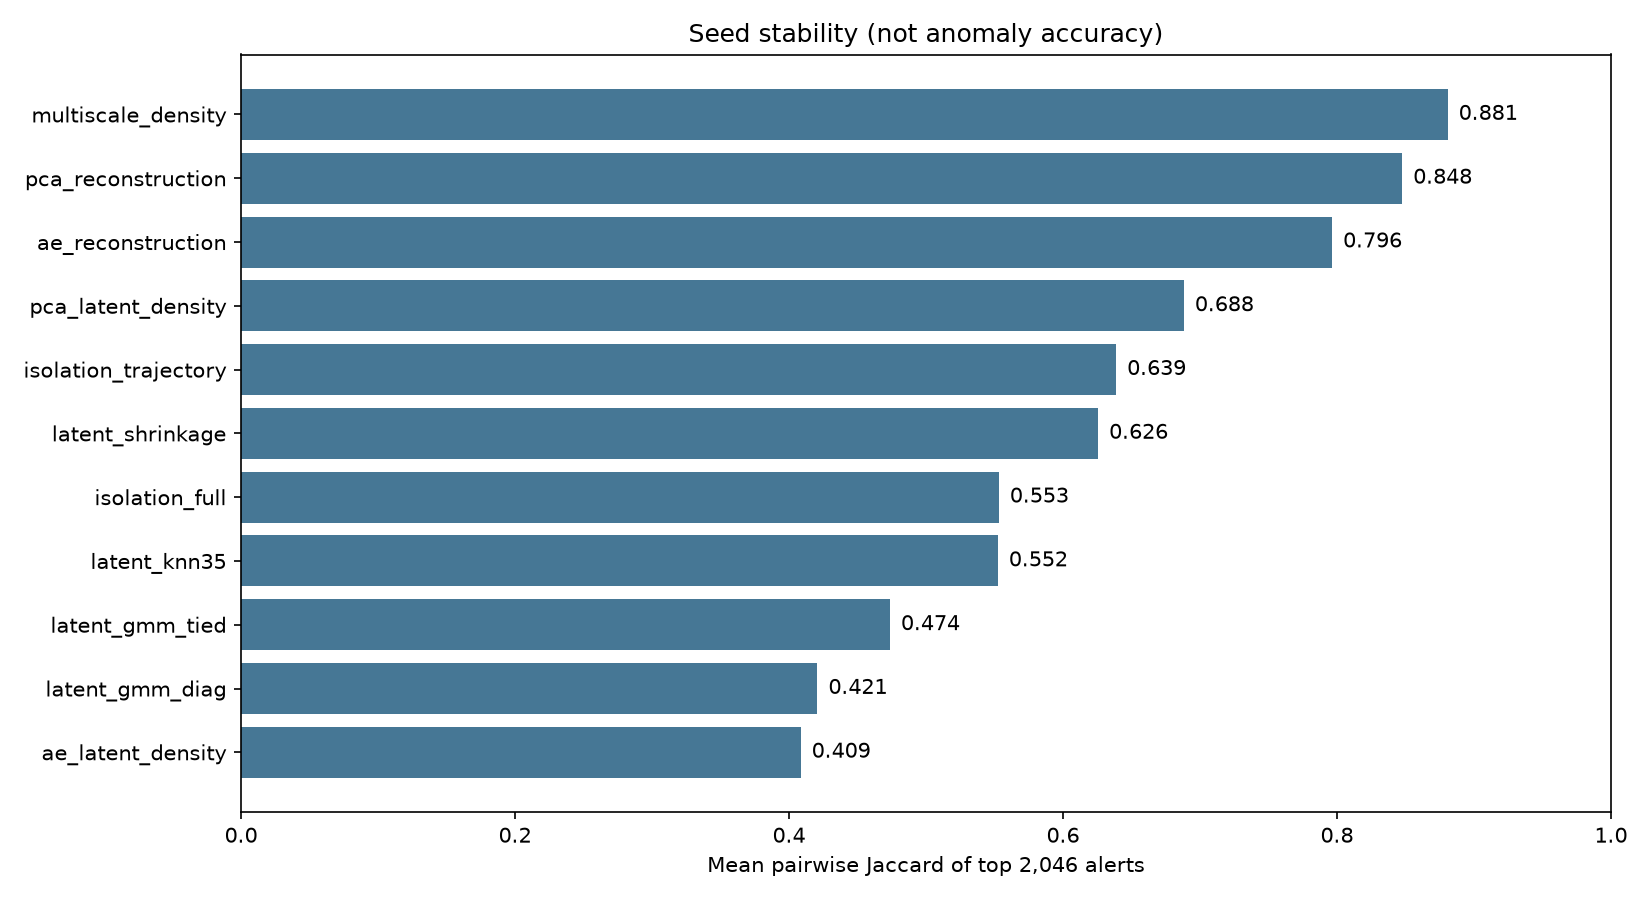

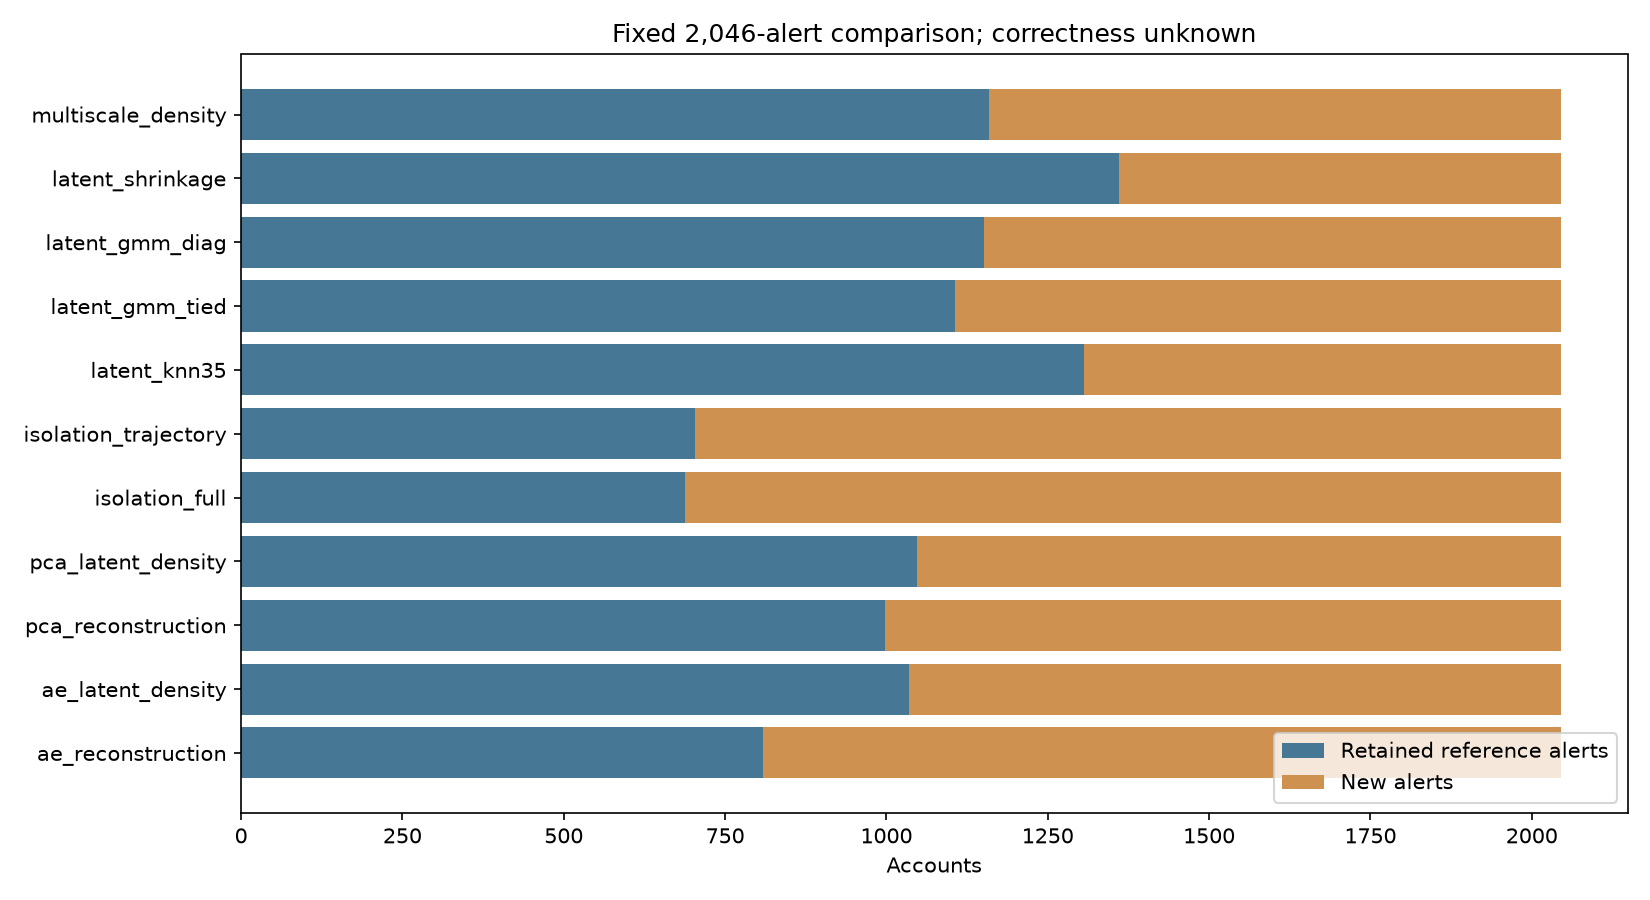

In [9]:
display(Image(filename=str(study.OUT / "figures/seed_stability.png")))
display(Image(filename=str(study.OUT / "figures/alert_comparison.png")))

## 8. Synthetic Sensitivity — Not Validation Accuracy

synthetic_auc  increased_fraction
kind             method                                                 
oscillation      ae_latent_density          0.965532            0.994667
                 ae_reconstruction          0.977571            1.000000
                 isolation_full             0.679337            1.000000
                 isolation_trajectory       0.655173            0.998000
                 pca_latent_density         0.999984            1.000000
                 pca_reconstruction         0.999984            1.000000
persistent_shift ae_latent_density          0.604927            0.689333
                 ae_reconstruction          0.666227            0.928667
                 isolation_full             0.526569            0.736667
                 isolation_trajectory       0.456364            0.026000
                 pca_latent_density         0.816133            0.931333
                 pca_reconstruction         0.561143            0.718667
spike_period1    ae_latent_density          0.977973            0.980667
                 ae_reconstruction          0.876552            1.000000
                 isolation_full             0.602403            0.991333
                 isolation_trajectory       0.647681            0.988667
                 pca_latent_density         0.974747            0.996000
                 pca_reconstruction         0.981237            1.000000
spike_period2    ae_latent_density          0.975563            0.977333
                 ae_reconstruction          0.872957            0.998667
                 isolation_full             0.588159            0.968667
                 isolation_trajectory       0.650647            0.992667
                 pca_latent_density         0.978841            0.995333
                 pca_reconstruction         0.975319            0.999333
spike_period3    ae_latent_density          0.976016            0.981333
                 ae_reconstruction          0.893825            0.999333
                 isolation_full             0.591724            0.986000
                 isolation_trajectory       0.645518            0.992667
                 pca_latent_density         0.988925            0.998000
                 pca_reconstruction         0.984036            0.999333
spike_period4    ae_latent_density          0.976787            0.973333
                 ae_reconstruction          0.896921            1.000000
                 isolation_full             0.670336            0.999333
                 isolation_trajectory       0.677415            0.998000
                 pca_latent_density         0.981152            0.993333
                 pca_reconstruction         0.982289            1.000000

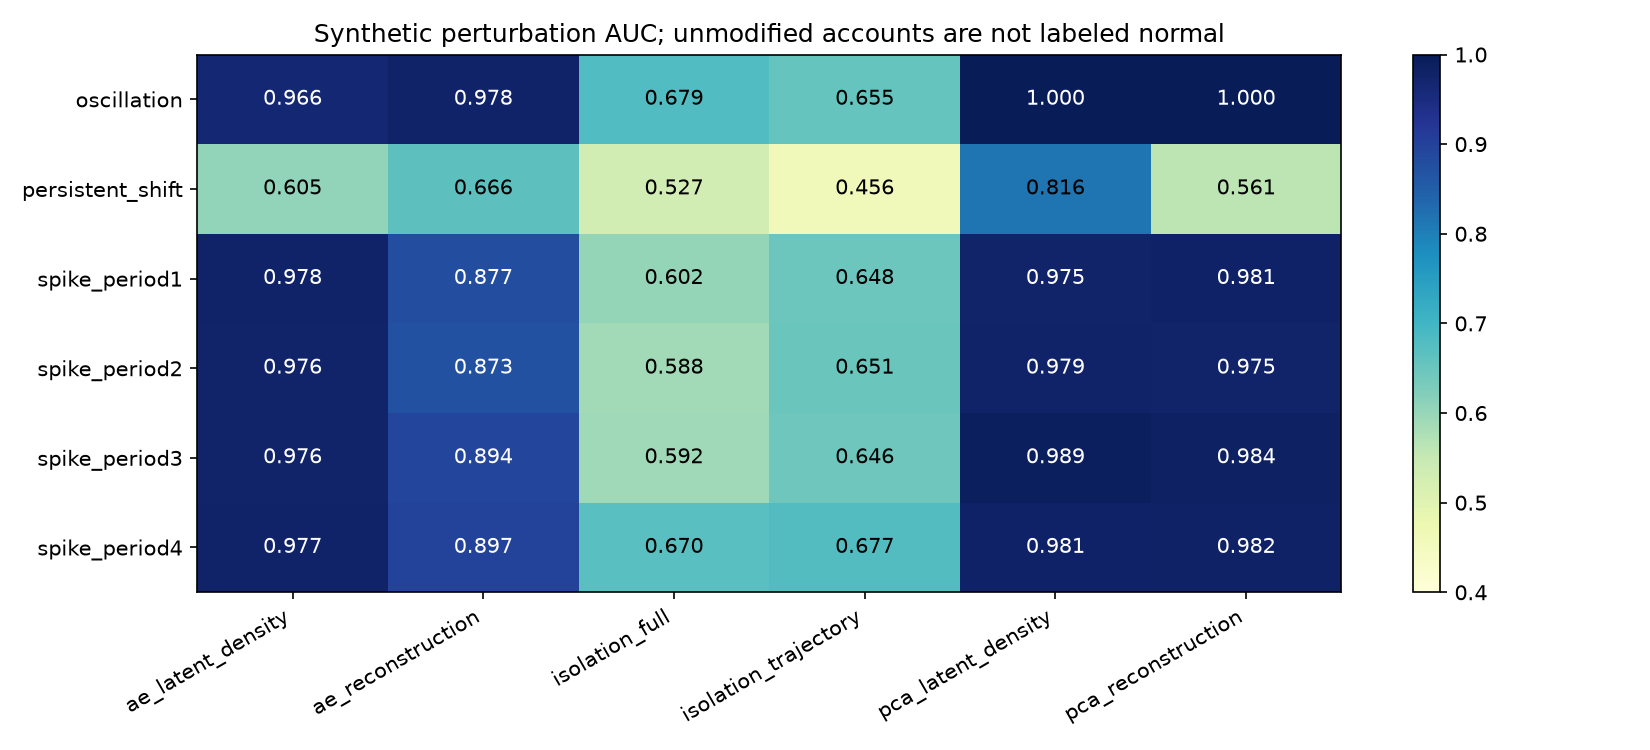

In [10]:
stress = pd.read_parquet(study.OUT / "stress.parquet")
display(stress.groupby(["kind", "method"])[["synthetic_auc", "increased_fraction"]].mean())
display(Image(filename=str(study.OUT / "figures/synthetic_sensitivity.png")))

สร้าง perturbation เฉพาะ held-out rows: เพิ่ม activity/security-related values ทีละช่วง 1–4,
สร้าง oscillation และ persistent shift. มี 500 บัญชีต่อ fold ของ seed แรก.
บัญชีเดิมไม่ได้มี label ว่า normal จึงใช้ผลนี้ดู blind spots เท่านั้น;
การเพิ่มค่าบางตัวแบบนี้ไม่ครอบคลุม anomaly ทุกชนิด และไม่ใช้เลือก threshold/weights.
ตารางนี้ครอบคลุม base methods 6 ตัว ไม่ใช่การประเมินทุก 11 ตัว

## 9. Alert Budget & Changed Accounts

In [11]:
display(pd.read_parquet(study.OUT / "budget_sensitivity.parquet"))
row_audit = pd.read_parquet(study.OUT / "candidate_row_audit.parquet")
display(row_audit.groupby("change").size().rename("accounts"))
display(row_audit[row_audit.change == "added"].sort_values("multiscale_density", ascending=False).head(20))

,alerts,rate,retained,added,removed
0,1500,0.057940,1021,479,1025
1,1800,0.069528,1102,698,944
2,2046,0.079030,1159,887,887
3,2250,0.086909,1191,1059,855
4,2500,0.096566,1225,1275,821
5,3000,0.115879,1280,1720,766


change
added          887
removed        887
unchanged    24115
Name: accounts, dtype: int64

,id,player_id,test_row_index,multiscale_density,prediction,seed_std,d4_k4,d4_k8,d8_k4,d8_k8,d16_k4,d16_k8,d24_k4,d24_k8,reference_prediction,change
14925,ANS14926,P024004,14925,0.997828,1,0.000667,0.999035,0.988996,0.999421,0.999421,0.998649,0.999035,0.999035,0.999035,0,added
21092,ANS21093,P005881,21092,0.994691,1,0.000486,0.998649,0.995560,0.999035,0.999035,0.991699,0.996718,0.992471,0.993243,0,added
24528,ANS24529,P008097,24528,0.994353,1,0.000577,0.998263,0.992471,0.999035,0.999035,0.990154,0.995946,0.992085,0.997490,0,added
6981,ANS06982,P008884,6981,0.994305,1,0.000486,0.998649,0.997490,0.995560,0.998649,0.991699,0.996718,0.988610,0.997876,0,added
3395,ANS03396,P014090,3395,0.993292,1,0.000583,0.998649,0.998263,0.998263,0.997104,0.994402,0.995946,0.992857,0.984363,0,added
18620,ANS18621,P022693,18620,0.991361,1,0.001270,0.995946,0.997876,0.996718,0.989382,0.989382,0.988224,0.987838,0.989382,0,added
6816,ANS06817,P021920,6816,0.990782,1,0.002136,0.995560,0.997490,0.990541,0.995946,0.981274,0.995560,0.980888,0.987838,0,added
8989,ANS08990,P003412,8989,0.990444,1,0.001777,0.997876,0.997876,0.995174,0.993243,0.983977,0.994402,0.983205,0.984749,0,added
12483,ANS12484,P020448,12483,0.990106,1,0.001650,0.993629,0.995560,0.990541,0.994788,0.983205,0.994788,0.982819,0.988996,0,added
17937,ANS17938,P012410,17937,0.987597,1,0.000701,0.994402,0.997490,0.990154,0.991699,0.979344,0.989382,0.978958,0.984363,0,added


Budget sensitivity ยังไม่มี F3 จึงไม่อ้างว่า 2,250 หรือ 3,000 ดีกว่า 2,046.
การขยาย alerts ช่วย positive-class recall ได้เมื่อ ranking เดิม แต่มีต้นทุน false positives และ macro F3 ยังอาจลดลง

## 10. Reproduce Saved Predictions

In [12]:
if RUN_FULL_VERIFICATION:
    study.verify()
    refinement.verify()
    multiscale.verify()
proof = json.loads((study.OUT / "verification.json").read_text())
display(pd.Series({k:v for k,v in proof.items() if k != "models"}))
display(pd.Series(json.loads((multiscale.OUT / "verification.json").read_text())))

bundles                             9
heldout_rows_recomputed         77667
score_values_recomputed        466002
fold_preprocessing_verified      True
heldout_disjoint                 True
dtype: object

score_values_recomputed    621336
models                         72
bundles                         9
dtype: int64

## 11. Submission — Only Task5 Changes

In [13]:
if EXPORT_CSV:
    report.export()
display(pd.Series(report.verify_export()))
print("CSV:", report.DEST)
print("ยังไม่มีคะแนน Kaggle ของไฟล์นี้ และไม่มีการ upload อัตโนมัติ")

path                                          /Users/meng/dev/MyUniversity/CPE342-MachineLea...
sha256                                        844d1efe84bdb043a6a566d0adfcee76060401b13a887e...
rows                                                                                      25889
alerts                                                                                     2046
ids_and_task1_to4_literal_fields_preserved                                                 True
task5_verified_against_saved_scores                                                        True
reference_sha256                              cd5725c7e9994d60a05ad31f917107d92e268f9833c0c6...
dtype: object

CSV: /Users/meng/dev/MyUniversity/CPE342-MachineLearning/CPE342-Kaggle/submission/kaggle_t12345_t1_slow800_bagging_v4_t3_conditional_quantile_v1_t4_resnet18_cosine18_tta_v1_t5_multiscale_representation_v1.csv
ยังไม่มีคะแนน Kaggle ของไฟล์นี้ และไม่มีการ upload อัตโนมัติ


## 12. Findings & Limitations

- AE + full-covariance GMM มี seed Jaccard ประมาณ 0.409; เปลี่ยน density estimator ช่วยบางส่วน แต่ยังแปรปรวน
- Multi-resolution linear density มี seed Jaccard ประมาณ 0.881 จึงเป็น candidate ที่เลือกสำหรับการทดลองครั้งนี้
- เทียบ reference: คง 1,159 alerts, เพิ่ม 887 และถอด 887; เป็นการเปลี่ยนวิธีค่อนข้างมาก
- ไม่มีหลักฐานว่าคะแนนจะสูงกว่า **0.81771**; ต้องรายงานผลหลังส่งจริงและระวัง Public LB overfitting
- ไม่มี clean-normal training, anomaly labels หรือ ground-truth validation; normal player clusters ที่หายากอาจถูก flag
- ทุก AE ครบ 45 epochs ในรอบนี้: loss ยังลดบางส่วน จึงไม่ถือว่าฝึกถึง optimum; การเพิ่ม epochs ต้องทดสอบ stability อีกครั้ง
- การเรียน representation จากข้อมูลปน anomaly อาจ reconstruct หรือ model anomaly ได้ดีเกินไป; ความซับซ้อนมากขึ้นไม่รับประกันผล


## 13. Reuse, Checkpoints & Research Background

In [14]:
import joblib
example_path = study.OUT / "seed173_fold1.joblib"
bundle = joblib.load(example_path)
net = study.AE(len(bundle["prep"].columns))
net.load_state_dict(bundle["state"])
net.eval()
print("AE checkpoint:", example_path)
print("Fold train / calibration / held:", len(bundle["fit"]), len(bundle["calibration"]), len(bundle["held"]))
print("Reuse requires the matching feature columns, preprocessing and latent-density calibration.")

AE checkpoint: /Users/meng/dev/MyUniversity/CPE342-MachineLearning/CPE342-Kaggle/Task5/models/results/representation_v1/seed173_fold1.joblib
Fold train / calibration / held: 14670 2589 8630
Reuse requires the matching feature columns, preprocessing and latent-density calibration.


**Run All** ใช้อ่านผลได้ทันที. เปิด `RUN_TRAINING=True` เพื่อ resume เฉพาะ bundles ที่ขาด;
ไฟล์ครบจะถูกโหลด. เปิด `RUN_FULL_VERIFICATION=True` เพื่อคำนวณ held-out scores ใหม่จาก weights.
หากเปลี่ยน config/code ให้ใช้ output version ใหม่ เพราะมี hash guard ป้องกันผสมคนละการทดลอง.

งานวิจัยประกอบแนวคิด representation + reconstruction + density:
[DAGMM, ICLR 2018](https://bzong.github.io/doc/iclr18-dagmm.pdf).
Implementation นี้เป็น two-stage density estimation ไม่ใช่การทำซ้ำ training objective หรือผลทดลองของ paper.
PCA/GMM/Isolation Forest/kNN/AE เป็นวิธีมาตรฐาน; contribution ของ notebook คือ protocol, temporal representation, ablations และการตรวจซ้ำบนข้อมูลนี้
